# 04 · Supplementary figures from the 2024–25 notebooks (v1.2)

The Colab notebooks of 2024–25 drew many more figures than the preprint uses. This notebook redraws the ones worth keeping with the cleaned data and the fixed code. The old code and what changed are listed in `docs/notebook_inventory.md`.

| Figure | What it shows | Old source (notebook, cell) |
|---|---|---|
| S2 | Grants per year, 15 most frequent funders | data_analysis c1760 |
| S3 | Each funder's grants by topic (%) | data_analysis c1826 |
| S4 | Topics by recipient country and Global North/South (%) | data_analysis c1810, c1849 |
| S5 | Topic similarity: word overlap and clustering | Patent_TopicModeling c77–c78 |
| S6 | Named researchers per year by gender, and women's share | data_analysis c1554 |
| S7 | Team gender by topic (%) | data_analysis c1851 |
| S8 | Researcher engagement over time, overall and by team gender | data_analysis c186, c461–c530 |
| S9 | Institution engagement over time, by topic | data_analysis c916–c995 |
| S10 | Funder country → recipient country flows (interactive HTML) | collab_network / Key_Players `create_sankey_diagrams_top20` |

Reusable code lives in `src/phagefund.py` (data) and `src/figures.py` (drawing).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import phagefund as pf
import figures as fg

DATA = ROOT / "data" / "processed" / "phage_funding_analysis.csv"
FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
fg.use_style()

d = pf.load(DATA)
TOPICS = ["Infectious disease control", "Bacterial genetics and mechanisms",
          "Antibiotic resistance strategies", "Immunotherapy and targeted treatments"]
SHORT = {"Infectious disease control": "Infectious\ndisease", "Bacterial genetics and mechanisms": "Bacterial\ngenetics",
         "Antibiotic resistance strategies": "Antibiotic\nresistance", "Immunotherapy and targeted treatments": "Immuno-\ntherapy"}
dt = d[d.topic.isin(TOPICS)]
print(f"{len(d)} grants; {len(dt)} with one of the 4 topics")

802 grants; 801 with one of the 4 topics


## Figure S2. Funders over time
Ported from `plot_top_50_heatmap`. Counts only: the old version printed dollar amounts in every cell.

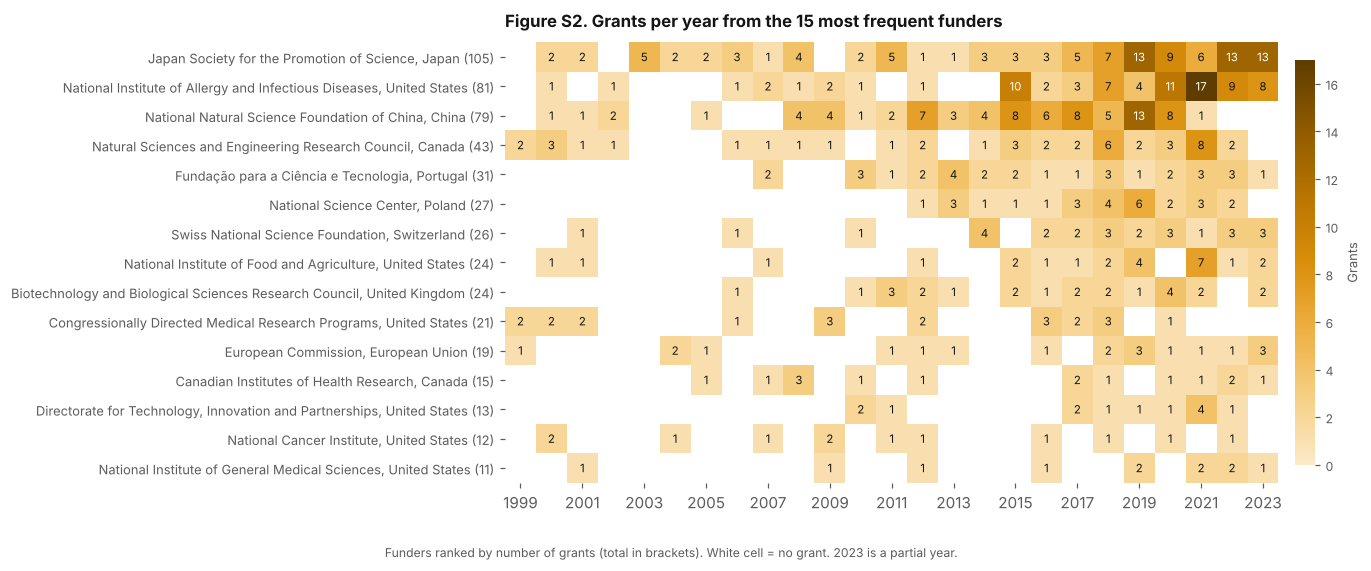

In [2]:
top = d[pf.FUNDER].value_counts().head(15).index
t = pd.crosstab(d[pf.FUNDER], d[pf.YEAR]).reindex(index=top, columns=range(1999, 2024), fill_value=0)
t.to_csv(TAB / "S14_funder_by_year.csv")
fig, ax = plt.subplots(figsize=(9.5, 5.2))
fg.heatmap(ax, t, label="Grants")
ax.set_xticks(range(0, 25, 2), [str(y) for y in range(1999, 2024, 2)])
fctry = d.groupby(pf.FUNDER)["Funder Country"].first()
ax.set_yticklabels([f"{n}, {fctry[n]} ({t.loc[n].sum()})" for n in t.index], fontsize=8.5)
ax.set_title("Figure S2. Grants per year from the 15 most frequent funders", pad=10)
fig.text(0.01, -0.02, "Funders ranked by number of grants (total in brackets). White cell = no grant. 2023 is a partial year.",
         fontsize=8, color=pf.INK2)
fg.save(fig, FIG, "FigS2_funders_by_year"); plt.show()

## Figure S3. Funders by topic
Each row is one funder's portfolio. Rows sum to 100%.

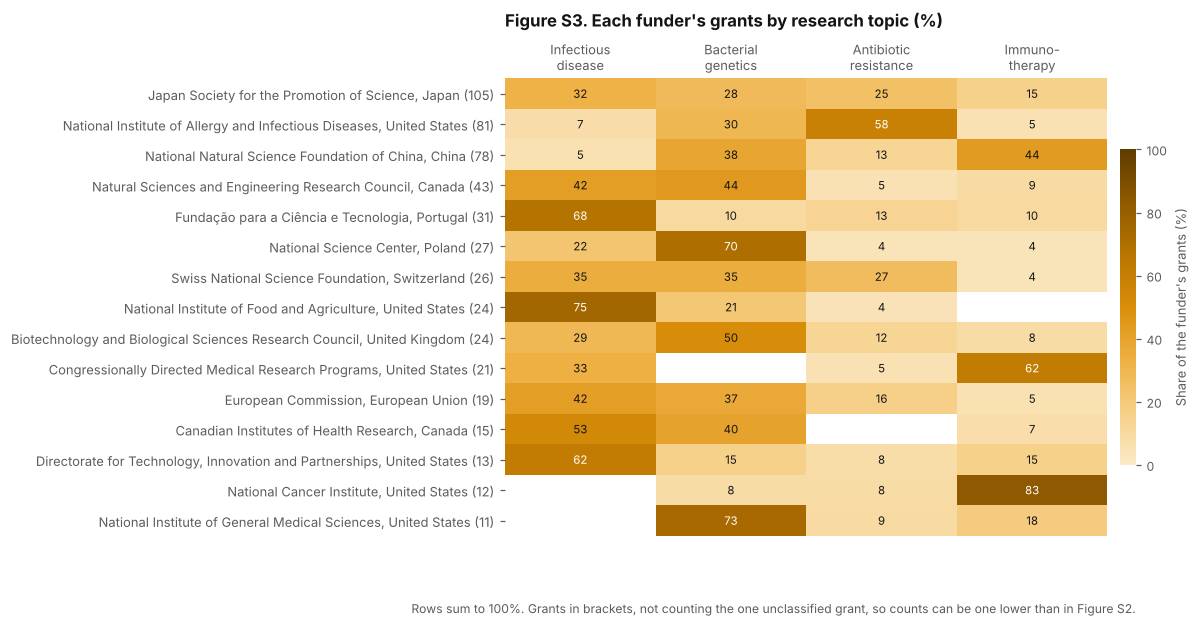

In [3]:
top = dt[pf.FUNDER].value_counts().head(15).index
s3 = pf.row_shares(dt[dt[pf.FUNDER].isin(top)], pf.FUNDER, "topic", rows=list(top))[TOPICS]
n = dt[pf.FUNDER].value_counts()
s3.to_csv(TAB / "S15_topic_share_by_funder.csv")
fig, ax = plt.subplots(figsize=(7.4, 5.4))
fg.heatmap(ax, s3.rename(columns=SHORT), label="Share of the funder's grants (%)", vmax=100)
fctry = d.groupby(pf.FUNDER)["Funder Country"].first()
ax.set_yticklabels([f"{f}, {fctry[f]} ({n[f]})" for f in s3.index], fontsize=8.5)
ax.xaxis.tick_top(); ax.tick_params(axis="x", length=0, labelsize=8.5)
ax.set_title("Figure S3. Each funder's grants by research topic (%)", pad=34)
fig.text(0.01, -0.02, "Rows sum to 100%. Grants in brackets, not counting the one unclassified grant, so counts can be one lower than in Figure S2.", fontsize=8, color=pf.INK2)
fg.save(fig, FIG, "FigS3_topic_by_funder"); plt.show()

## Figure S4. Topics by recipient country
Fractional counting, as in the main analysis: a grant with *k* recipient institutions counts 1/*k* for each institution's country.

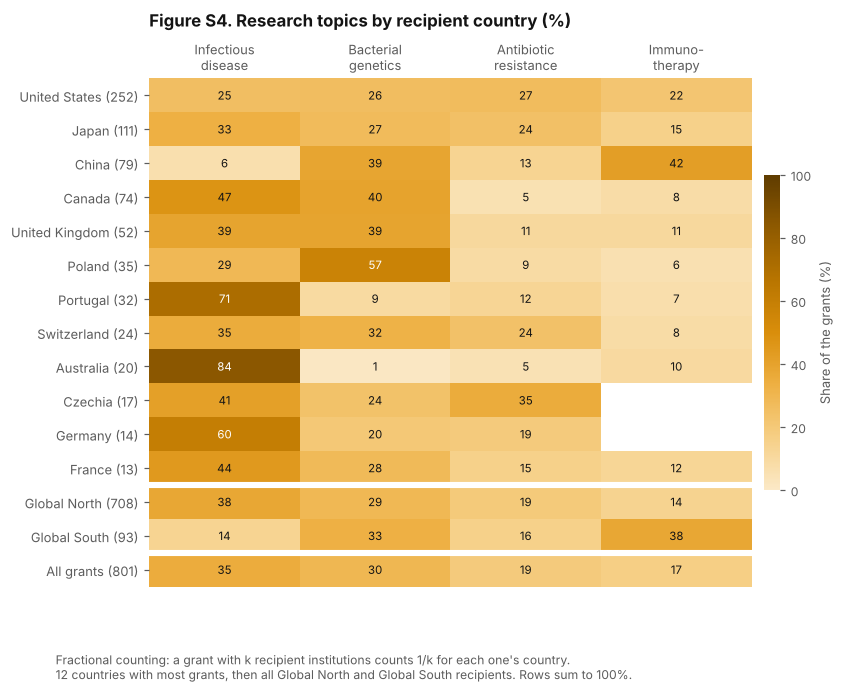

In [4]:
long = pf.aligned_long(dt, "receiver_country_list").merge(dt[["Grant ID", "topic"]], on="Grant ID")
topc = long.groupby("receiver_country_list")["grant_frac"].sum().sort_values(ascending=False).head(12).index
c = pf.row_shares(long[long.receiver_country_list.isin(topc)], "receiver_country_list", "topic",
                  weight="grant_frac", rows=list(topc))[TOPICS]
ns = pf.aligned_long(dt, "receiver_north_south_list").merge(dt[["Grant ID", "topic"]], on="Grant ID")
g = pf.row_shares(ns[ns.receiver_north_south_list.isin(["Global North", "Global South"])],
                  "receiver_north_south_list", "topic", weight="grant_frac")[TOPICS]
allrow = pd.DataFrame([pf.row_shares(dt.assign(all="All grants"), "all", "topic").loc["All grants", TOPICS]])
s4 = pd.concat([c, g, allrow]); s4.to_csv(TAB / "S16_topic_share_by_recipient.csv")
nfrac = pd.concat([long.groupby("receiver_country_list")["grant_frac"].sum(),
                   ns.groupby("receiver_north_south_list")["grant_frac"].sum(), pd.Series({"All grants": len(dt)})])
fig, ax = plt.subplots(figsize=(7.4, 6.0))
fg.heatmap(ax, s4.rename(columns=SHORT), label="Share of the grants (%)", vmax=100)
ax.set_yticklabels([f"{r} ({nfrac[r]:.0f})" for r in s4.index], fontsize=8.5)
ax.axhline(len(c) - 0.5, color="white", lw=4); ax.axhline(len(c) + 1.5, color="white", lw=4)
ax.xaxis.tick_top(); ax.tick_params(axis="x", length=0, labelsize=8.5)
ax.set_title("Figure S4. Research topics by recipient country (%)", pad=34)
fig.text(0.01, -0.03, "Fractional counting: a grant with k recipient institutions counts 1/k for each one's country.\n"
         "12 countries with most grants, then all Global North and Global South recipients. Rows sum to 100%.",
         fontsize=8, color=pf.INK2)
fg.save(fig, FIG, "FigS4_topic_by_recipient"); plt.show()

## Figure S5. How distinct are the four topics?
The old notebook compared the LDA topic word lists. Here the words come from the grants as assigned in 2024 (`topic_probability_2024.pkl`), so the figure describes the topics used in the paper. Words used in more than half of all grants (such as *phage*) are removed so the lists show what sets each topic apart.

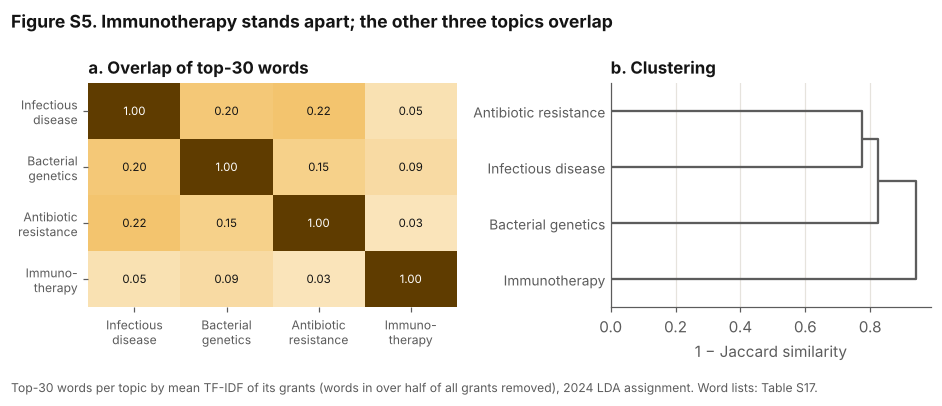

In [5]:
texts = pd.read_pickle(ROOT / "data" / "raw" / "topic_probability_2024.pkl").reset_index()[["Grant ID", "Cleaned_Text"]]
tt = dt[["Grant ID", "topic"]].merge(texts, on="Grant ID")
words = pf.distinctive_words(tt["Cleaned_Text"], tt["topic"], n=30)
words = {k: words[k] for k in TOPICS}
sim = pf.jaccard_matrix(words)
pd.DataFrame(words).to_csv(TAB / "S17_topic_distinctive_words.csv", index=False)
sim.to_csv(TAB / "S18_topic_jaccard.csv")
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.4), gridspec_kw={"width_ratios": [1.15, 1]})
fg.heatmap(axes[0], sim.rename(index=SHORT, columns=SHORT), fmt="{:.2f}", label="Jaccard", vmax=1, cbar=False)
axes[0].tick_params(axis="both", labelsize=8)
axes[0].set_title("a. Overlap of top-30 words")
fg.topic_dendrogram(axes[1], sim.rename(index=lambda x: SHORT[x].replace("-\n", "").replace("\n", " ")))
axes[1].set_title("b. Clustering")
fig.suptitle("Figure S5. Immunotherapy stands apart; the other three topics overlap", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.text(0.01, -0.04, "Top-30 words per topic by mean TF-IDF of its grants (words in over half of all grants removed), 2024 LDA assignment. Word lists: Table S17.",
         fontsize=8, color=pf.INK2)
fig.tight_layout(); fg.save(fig, FIG, "FigS5_topic_similarity"); plt.show()

## Figure S6. Researchers by gender
Ported from `count_gender_by_year`. Two panels instead of one plot with two y-axes.

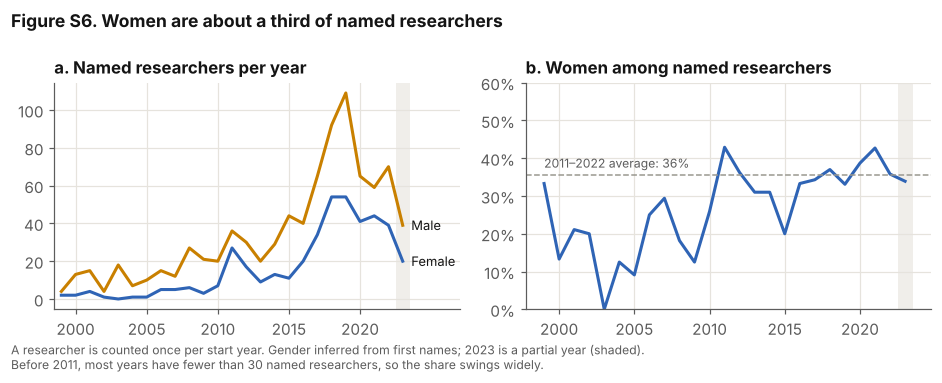

In [6]:
r = pf.researchers_by_gender_year(d); r.to_csv(TAB / "S19_researchers_by_gender_year.csv")
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.2))
ax = axes[0]
for gname, col in [("Male", pf.PALETTE[0]), ("Female", pf.PALETTE[1])]:
    ax.plot(r.index, r[gname], color=col, lw=2)
    ax.text(2023.6, r[gname].iloc[-1], gname, color=pf.INK, fontsize=8.5, va="center")
ax.set_title("a. Named researchers per year"); ax.set_xlim(1998.5, 2027); ax.set_xticks(range(2000, 2021, 5))
ax = axes[1]
m = r.loc[2011:2022]
share = (m["Female"].sum() / (m["Male"].sum() + m["Female"].sum()) * 100)
ax.plot(r.index, r["Female share (%)"], color=pf.PALETTE[1], lw=2)
ax.axhline(share, color=pf.NEUTRAL, lw=1, ls="--")
ax.text(1999, share + 2, f"2011–2022 average: {share:.0f}%", fontsize=8, color=pf.INK2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, 60)
ax.set_title("b. Women among named researchers")
for a in axes:
    a.axvspan(2022.5, 2023.5, color=pf.GRID, alpha=0.6, lw=0)
fig.suptitle("Figure S6. Women are about a third of named researchers", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.text(0.01, -0.04, "A researcher is counted once per start year. Gender inferred from first names; 2023 is a partial year (shaded).\n"
         "Before 2011, most years have fewer than 30 named researchers, so the share swings widely.", fontsize=8, color=pf.INK2)
fig.tight_layout(); fg.save(fig, FIG, "FigS6_researchers_by_gender"); plt.show()

## Figure S7. Team gender by topic
Same exclusive groups as Table 4: male only, female only, mixed, no named researcher.

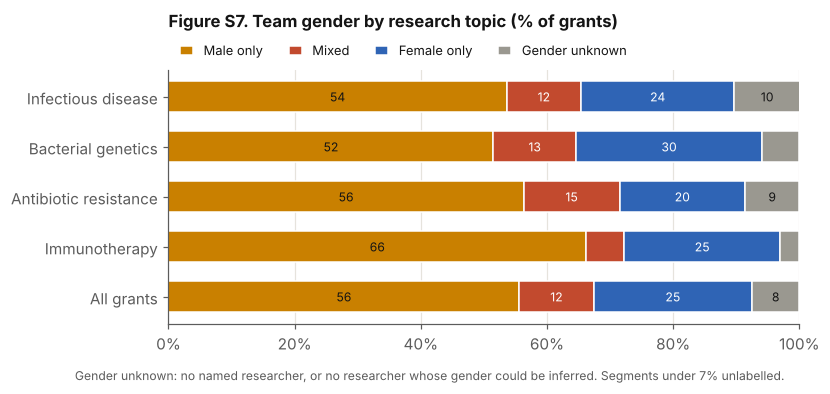

In [7]:
groups = ["Male only", "Mixed", "Female only", "Gender unknown"]
s7 = pf.row_shares(dt, "topic", "team_gender", rows=TOPICS)[groups]
s7.loc["All grants"] = pf.row_shares(d.assign(all="All grants"), "all", "team_gender").loc["All grants", groups]
s7.to_csv(TAB / "S20_team_gender_by_topic.csv")
cols = [pf.PALETTE[0], pf.PALETTE[2], pf.PALETTE[1], pf.NEUTRAL]
fig, ax = plt.subplots(figsize=(7.4, 3.0))
left = np.zeros(len(s7))
labels = [SHORT.get(x, x).replace("-\n", "").replace("\n", " ") for x in s7.index]
for gname, col in zip(groups, cols):
    ax.barh(labels, s7[gname], left=left, color=col, height=0.62, label=gname, edgecolor="white", linewidth=1)
    for i, (l, v) in enumerate(zip(left, s7[gname])):
        if v >= 7:
            ax.text(l + v / 2, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color=pf.INK if col in (pf.PALETTE[0], pf.NEUTRAL) else "white")
    left += s7[gname].values
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8.5, handlelength=1)
ax.set_title("Figure S7. Team gender by research topic (% of grants)", pad=28)
fig.text(0.01, -0.06, "Gender unknown: no named researcher, or no researcher whose gender could be inferred. Segments under 7% unlabelled.", fontsize=8, color=pf.INK2)
fg.save(fig, FIG, "FigS7_team_gender_by_topic"); plt.show()

## Figure S8. Researcher engagement over time
Per-year labels as in the notebooks' `classify_entities_func`, with three fixes: real years on the x-axis, zeros instead of gaps, and one end year (2023) for every subset. The old female-funder plot reused the male data and is not redrawn.

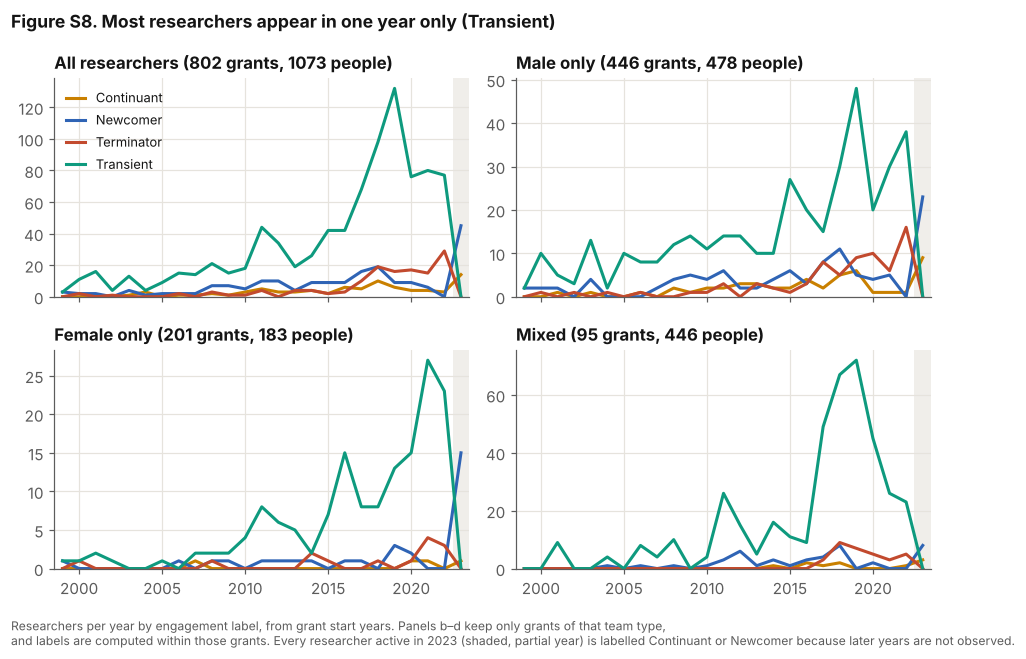

In [8]:
panels = [("All researchers", d)] + [(g, d[d.team_gender == g]) for g in ["Male only", "Female only", "Mixed"]]
tabs = {name: pf.engagement_by_year(sub) for name, sub in panels}
pd.concat(tabs, names=["group"]).to_csv(TAB / "S21_researcher_engagement_by_year.csv")
fig, axes = plt.subplots(2, 2, figsize=(8.6, 5.6), sharex=True)
for ax, (name, sub) in zip(axes.flat, panels):
    tot = pf.classify_engagement(sub).value_counts()
    fg.engagement_panel(ax, tabs[name], title=f"{name} ({len(sub)} grants, {tot.sum()} people)", legend=(name == "All researchers"))
fig.suptitle("Figure S8. Most researchers appear in one year only (Transient)", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.text(0.01, -0.05, "Researchers per year by engagement label, from grant start years. Panels b–d keep only grants of that team type,\nand labels are computed within those grants. "
         "Every researcher active in 2023 (shaded, partial year) is labelled Continuant or Newcomer because later years are not observed.",
         fontsize=8, color=pf.INK2)
fig.tight_layout(); fg.save(fig, FIG, "FigS8_researcher_engagement"); plt.show()

## Figure S9. Institution engagement by topic
Each panel uses only that topic's grants. In the old notebook several of these sections read the full dataset, so the four topics looked the same.

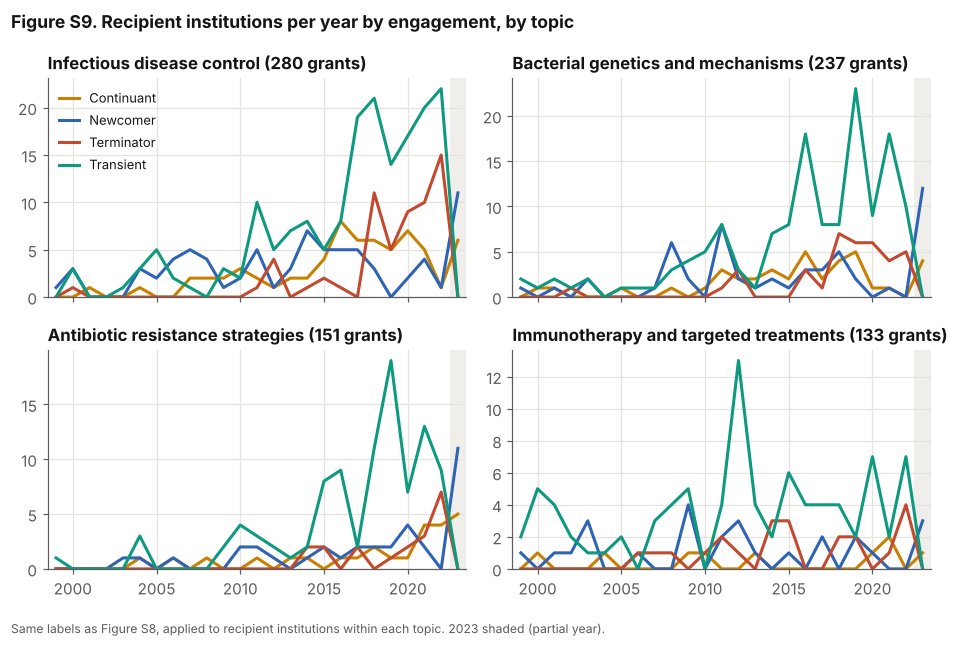

In [9]:
tabs9 = {t: pf.engagement_by_year(dt[dt.topic == t], col="receiver_org_list", sep=";") for t in TOPICS}
pd.concat(tabs9, names=["topic"]).to_csv(TAB / "S22_institution_engagement_by_topic.csv")
fig, axes = plt.subplots(2, 2, figsize=(8.6, 5.6), sharex=True)
for ax, t in zip(axes.flat, TOPICS):
    nt = (dt.topic == t).sum()
    fg.engagement_panel(ax, tabs9[t], title=f"{t} ({nt} grants)", legend=(t == TOPICS[0]))
    ax.title.set_fontsize(10)
fig.suptitle("Figure S9. Recipient institutions per year by engagement, by topic", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.text(0.01, -0.03, "Same labels as Figure S8, applied to recipient institutions within each topic. 2023 shaded (partial year).",
         fontsize=8, color=pf.INK2)
fig.tight_layout(); fg.save(fig, FIG, "FigS9_institution_engagement_by_topic"); plt.show()

## Figure S10. Funding flows between countries
Interactive HTML (opens in a browser; loads plotly from its CDN). All flows are in Table S23.

In [10]:
flows = pf.country_flows(d)
(flows.assign(usd_m=(flows.usd_frac / 1e6).round(2), grants_frac=flows.grants_frac.round(2)).drop(columns="usd_frac")
 .rename(columns={"Recipient country": "Recipient country", "grants_frac": "Grants (fractional)", "domestic": "Domestic", "usd_m": "USD (M, fractional)"})
 .to_csv(TAB / "S23_country_flows.csv", index=False))
drawn = fg.sankey_html(flows, FIG / "FigS10_country_flows.html", top=25,
                       title="Figure S10. Funding from funder country to recipient country, 25 largest flows (USD M). Grey = domestic, amber = cross-border")
print(f"Drawn flows cover {drawn.usd_frac.sum() / flows.usd_frac.sum() * 100:.1f}% of funding; "
      f"cross-border share of all funding: {flows.loc[~flows.domestic, 'usd_frac'].sum() / flows.usd_frac.sum() * 100:.1f}%")

Drawn flows cover 95.6% of funding; cross-border share of all funding: 8.6%
